In [1]:
import pandas as pd
import numpy as np
import math
import copepodTCR as cpp
import seaborn as sn
from matplotlib import pyplot as plt

## plotting styles
plt.style.use('default')
color_basic = '#FFA500'
color_copepodTCR = '#015396'

## formula to calculate sensitivity and specificity based on the number of true-false positive-negatives
def calculate_tpr_fpr(tp, tn, fp, fn):

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    return tpr, 1 - fpr

# Figure 2: Performance of copepodTCR’s interpretation framework on simulated data.

Line plots show the
specificity and sensitivity of the mixture model. The shaded region around each line shows the 95% confidence
interval, measured using bootstrapping with 1,000 samples. Bar plots show the percentage of simulations in
which all true cognate (and no false positive) peptides were assigned by the decision-tree algorithm to the
“cognate” list, or in which all cognate peptides were present in the “candidate” list, respectively. The black
line on each bar shows the 95% confidence interval, measured using bootstrapping with 1,000 samples.

In [2]:
# Model validation data

## DATA: spanning neg_share from 0.3 to 0.9
table = pd.read_csv('./data/insilico-simulations.tsv', sep = '\t', low_memory=False)
### control = 0 activated pools
control = table[table['error'] == 100]
print(f'Simulations with non-fixed neg_shares: total {len(table)}, negative data {len(control)}')
### with 1 erroneous non-activated pool
table_error = table[(table['error'] == 1)]
### with 0 erroneous non-activated pools
table = table[(table['error'] == 0)]


## data with fixed neg_share =0.3 or =0.6
table_ns = pd.read_csv('./data/insilico-simulations_fixed-negshare.tsv', sep = '\t')
### control = 0 activated pools
control_ns = table_ns[table_ns['error'] == 100]
print(f'Simulations with fixed neg_shares: total {len(table_ns)}, negative data {len(control_ns)}')
### with 0 erroneous non-activated pools
table_ns = table_ns[table_ns['error'] == 0]

Simulations with non-fixed neg_shares: total 9720, negative data 3240
Simulations with fixed neg_shares: total 6318, negative data 2106


## B

Sensitivity and specificity of the mixture model
depending on the signal intensity (mu_signal), modeled here as a percentage of activated T cells per well.

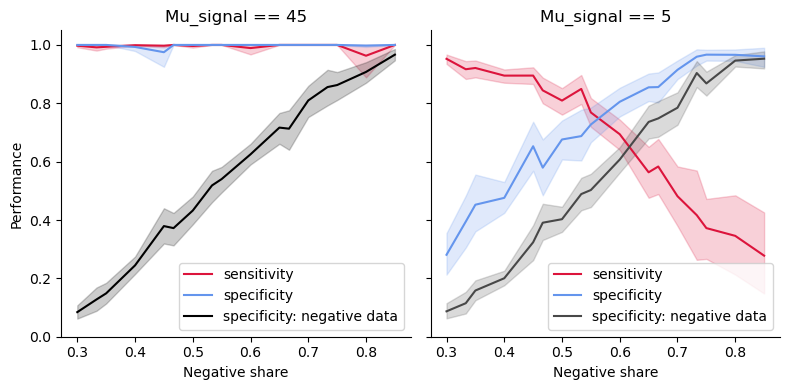

In [3]:
fig, axes = plt.subplots(1, 2, figsize = (8, 4), sharey=True)

## selecting data subsets with high activation signal
d1 = table_ns[table_ns['mu_signal'] == 45]
c1 = control_ns[control_ns['mu_signal'] == 45]

ax = axes[0]
## sensitivity
sn.lineplot(data = d1, x = 'neg_share', y = 'TPR', color = 'Crimson', label = 'sensitivity', ax = ax)
## specificity
sn.lineplot(data = d1, x = 'neg_share', y = 'FPR', color = 'CornflowerBlue', label = 'specificity', ax = ax)
## specificity on negative data (with 0 activated pools)
sn.lineplot(data = c1, x = 'neg_share', y = 'FPR', color = 'black', label = 'specificity: negative data', ax = ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Performance')
ax.set_xlabel('Negative share')
ax.set_title('Mu_signal == 45')

## selecting data subsets with high activation signal
d1 = table_ns[table_ns['mu_signal'] == 5]
c1 = control_ns[control_ns['mu_signal'] == 5]

ax = axes[1]
## sensitivity
sn.lineplot(data = d1, x = 'neg_share', y = 'TPR', color = 'Crimson', label = 'sensitivity', ax = ax)
## specificity
sn.lineplot(data = d1, x = 'neg_share', y = 'FPR', color = 'CornflowerBlue', label = 'specificity', ax = ax)
## specificity on negative data (with 0 activated pools)
sn.lineplot(data = c1, x = 'neg_share', y = 'FPR', color = '#484848', label = 'specificity: negative data', ax = ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Performance')
ax.set_xlabel('Negative share')
ax.set_title('Mu_signal == 5')

sn.despine()
plt.tight_layout()

## C-D

C. Percentage of simulations with a correctly identified set of cognate peptides tested with different signal
intensities. D. Percentage of simulations with a correctly identified set of cognate peptides tested with and
without experimental errors.

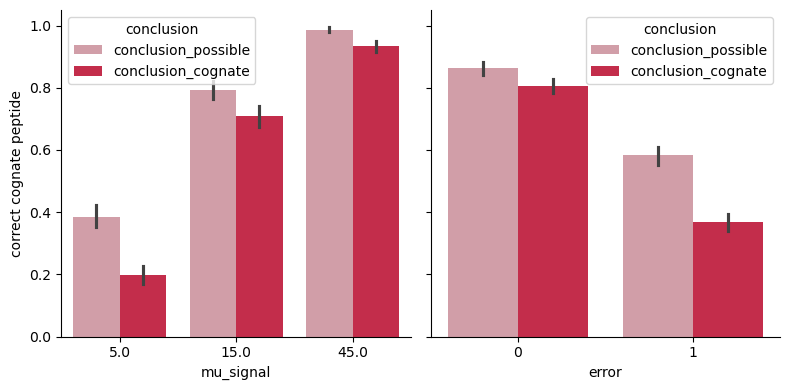

In [4]:
## conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
## conclusion_possible == True => correct cognate peptide is present in the list of peptide candidates
fig, axes = plt.subplots(1, 2, figsize = (8, 4), sharey = True)

color_palette = {'conclusion_possible': '#DA95A3', 'conclusion_cognate': '#DC143C'}

## different signal intensities
ax = axes[0]
plot_data = table_ns.melt(id_vars = 'mu_signal', value_vars = ['conclusion_cognate', 'conclusion_possible'], var_name = 'conclusion', value_name = 'proportion')
sn.barplot(data = plot_data, x = 'mu_signal', y = 'proportion', hue = 'conclusion', hue_order = ['conclusion_possible', 'conclusion_cognate'], palette=color_palette, ax=ax)

ax.set_ylim(0, 1.05)
ax.set_ylabel('correct cognate peptide')

## presence of errors
ax = axes[1]
plot_data = pd.concat([table_error[table_error['mu_signal'] == 45], table[table['mu_signal'] == 45]]).melt(id_vars='error', value_vars=['conclusion_cognate', 'conclusion_possible'], var_name='conclusion', value_name='proportion')
sn.barplot(data=plot_data, x='error', y='proportion', hue='conclusion', hue_order=['conclusion_possible', 'conclusion_cognate'], palette=color_palette, ax=ax)

sn.despine()
plt.tight_layout()

## E
In CPP schemes, each peptide is assigned a unique “address”, defined as the unique combination
of pools to which the peptide is added. We refer to the number of pools in the address as “peptide occurrence”, denoted
by r. In matrix pooling, r is always equal to 2. The number of pools required for the CPP scheme depends on the number
of peptides, peptide occurrence, and the pooling method.

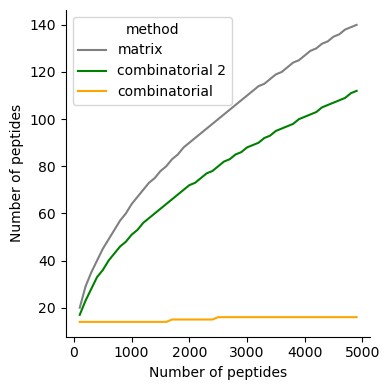

In [5]:
## selecting appropriate number of rows and columns for matrix pooling
def select_matrix(n):
    rows = int(math.sqrt(n))
    cols = math.ceil(n / rows)

    return rows, cols

## calculating number of pools required by each method
result_scheme = []
for i in range(100, 5000, 100):

    ### matrix
    nrows, ncols = select_matrix(i)
    result_scheme.append(['matrix', nrows+ncols, 2, i])

    ### CPP
    for j in range(5, 200):
        if math.comb(j, 2)*0.8 >= i:
            result_scheme.append(['combinatorial 2', j, 2, i])
            break
    found = False
    for j in range(5, 200):
        for iters in range(5, 200):
            if math.comb(j, iters)*0.8 >= i:
                if math.isclose((j - iters - 1)/j, 0.6, rel_tol=.1):
                    found = True
                    result_scheme.append(['combinatorial', j, iters, i])
                    break
        if found:
            break

result_scheme = pd.DataFrame(result_scheme, columns = ['method', 'n_pools', 'iters', 'len_lst'])

fig, axes = plt.subplots(figsize=(4, 4))
sn.lineplot(result_scheme, x = 'len_lst', y = 'n_pools', hue = 'method', palette = ['gray', 'green', color_basic])
axes.set_xlabel('Number of peptides')
axes.set_ylabel('Number of peptides')
sn.despine()
plt.tight_layout()

## F

Percentage of simulations in which at least one cognate peptide from the overlapping pair was identified correctly relative to the number of pools expected to be activated based on the pooling scheme. The range was generated using bootstrapping with 1,000 samples. Each box shows the interquartile range, with the horizontal line indicating the median; whiskers extend to the remaining data points. copepodTCR results are shown in blue, and basic combinatorial pooling results are shown in orange.

In [6]:
# Methods comparison data

## DATA: simulations with negative share fixed in 0.5-0.7 and 0.7-0.9 intervals
results = pd.read_csv('./data/insilico-simulations_methods-comparison_fixed-negshare.tsv', sep='\t')

## calculating sensitivity and specificity
tpr, fpr = calculate_tpr_fpr(results['TruePositive'], results['TrueNegative'], results['FalsePositive'], results['FalseNegative'])
results['Sensitivity'] = tpr
results['Specificity'] = fpr

## control == 0 activated pools
control = results[results['error'] == 100]
## with simulated 1 error
table_error = results[results['error'] == 1]
## with simulated 0 errors
table_noerror = results[results['error'] == 0]

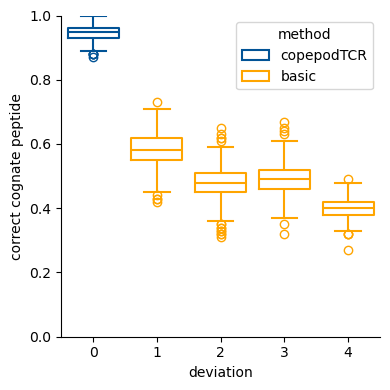

In [7]:
fig, axes = plt.subplots(1, 1, figsize=(4, 4))

## selecting subset with high activation signal and epitope_length = 8 because then the peptides are overlapping enough to share an epitope
subset = table_noerror[(table_noerror['ep_length'] == 8) & (table_noerror['mu_signal'] == 45)]
subset_outcomes = []

## parsing the subset to extract simulation scenarios in which at least one cognate peptide from the overlapping pair was identified correctly
for i in range(len(subset)):
    subset_true = subset['true_peptides'].iloc[i]
    subset_predicted = subset['predicted'].iloc[i]

    if type(subset_predicted) == str:
        subset_true = subset_true.split(', ')
        subset_predicted = subset_predicted.split(', ')
        for j in range(len(subset_predicted)):
            if subset_predicted[j] in subset_true:
                subset_outcomes.append([subset['method'].iloc[i], subset['# true act'].iloc[i], subset['iters'].iloc[i], True])
                break
            else:
                subset_outcomes.append([subset['method'].iloc[i], subset['# true act'].iloc[i], subset['iters'].iloc[i], False])
    else:
        subset_outcomes.append([subset['method'].iloc[i], subset['# true act'].iloc[i], subset['iters'].iloc[i], False])
subset_outcomes = pd.DataFrame(subset_outcomes, columns = ['method', '# true act', 'iters', 'outcome'])

## calculating the deviation from expected as the number of activated pools - peptide occurrence -1
subset_outcomes['deviation'] = subset_outcomes['# true act'] - subset_outcomes['iters'] - 1

bs_outcomes = []
for j in range(0, np.max(subset_outcomes['deviation']) + 1):
    subsubset = subset_outcomes[subset_outcomes['deviation'] == j]
    for i in range(1000):
        ## if there are not enough simjlations of a given type
        try:
            subset_comb = subsubset[subsubset['method'] == 'basic'].sample(100)
            comb_stat = len(subset_comb[subset_comb['outcome'] == True])/100
            bs_outcomes.append([j, comb_stat, 'basic'])
        except ValueError:
            pass
        try:
            subset_cop = subsubset[subsubset['method'] == 'copepodTCR'].sample(100)
            cop_stat = len(subset_cop[subset_cop['outcome'] == True])/100
            bs_outcomes.append([j, cop_stat, 'copepodTCR'])
        except ValueError:
            pass

bs_outcomes = pd.DataFrame(bs_outcomes, columns = ['deviation', '% true', 'method'])

sn.boxplot(x = bs_outcomes['deviation'], y = bs_outcomes['% true'], hue = bs_outcomes['method'], palette = [color_copepodTCR, color_basic], fill = False, ax = axes)
axes.set_xlabel('deviation')
axes.set_ylabel('correct cognate peptide')
axes.set_ylim(0, 1)

plt.tight_layout()
sn.despine()

## G
Percentage of simulations in which all true cognate (no false positives) were assigned by the decision-tree algorithm to the “cognate” list, or in which all cognate peptides were present in the “candidate” list. The black line on each bar shows the 95% confidence interval, measured using bootstrapping with 1,000 samples.

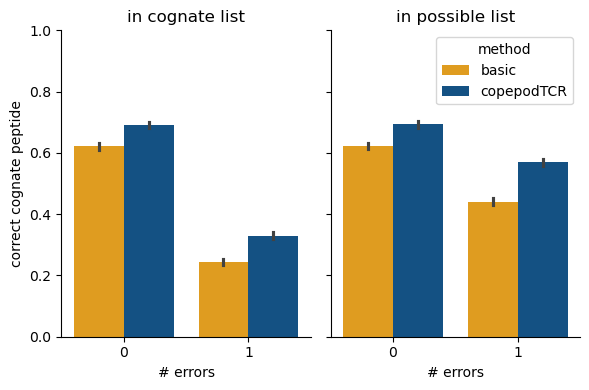

In [8]:
## conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
## conclusion_possible == True => correct cognate peptide is present in the list of peptide candidates
fig, axes = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

## selecting a subset with high activation signal
## results[error] != 100 ensures that it is not negative control data
subset = results[(results['mu_signal'] == 45) & (results['error'] != 100)]

## plotting results for presence of peptides in "cognate" list
ax = axes[0]
sn.barplot(data = subset, x = 'error', y = 'conclusion_cognate', hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax, legend = False)
ax.set_title('in cognate list')
ax.set_xlabel('# errors')
ax.set_ylabel('correct cognate peptide')
plt.ylim(0, 1)

## plotting results for presence of peptides in "candidate" list
ax = axes[1]
sn.barplot(subset, x = 'error', y = 'conclusion_possible', hue = 'method', palette = [color_basic, color_copepodTCR], ax = ax)
ax.set_title('in possible list')
ax.set_xlabel('# errors')
ax.set_ylabel('correct cognate peptide')
plt.ylim(0, 1)

plt.tight_layout()
sn.despine()